# Bank Customer Churn Prediction

This project uses supervised learning to identify bank customers who are likely to churn, and analyzes the main factors that drive customer retention.

**Dataset:** [Predicting Churn for Bank Customers (Kaggle)](https://www.kaggle.com/adammaus/predicting-churn-for-bank-customers) — 10,000 customers, 14 columns, binary target `Exited`.

## Contents

* [Part 1: Data Exploration](#Part-1:-Data-Exploration)
* [Part 2: Feature Preprocessing](#Part-2:-Feature-Preprocessing)
* [Part 3: Model Training and Result Evaluation](#Part-3:-Model-Training-and-Result-Evaluation)
* [Part 4: Feature Importance](#Part-4:-Feature-Importance)
* [Summary](#Summary)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

churn_df = pd.read_csv('data/bank.data.csv')
churn_df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# Part 1: Data Exploration

### Part 1.1: Understand the Raw Dataset

In [2]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [3]:
# number of unique values per column
churn_df.nunique()

RowNumber          10000
CustomerId         10000
Surname             2932
CreditScore          460
Geography              3
Gender                 2
Age                   70
Tenure                11
Balance             6382
NumOfProducts          4
HasCrCard              2
IsActiveMember         2
EstimatedSalary     9999
Exited                 2
dtype: int64

In [4]:
# target variable
y = churn_df['Exited']
y.value_counts(normalize=True)

Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

### Part 1.2: Understand the Features

In [5]:
# missing values
churn_df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [6]:
# numerical features
churn_df[['CreditScore', 'Age', 'Tenure', 'NumOfProducts', 'Balance', 'EstimatedSalary']].describe()

,CreditScore,Age,Tenure,NumOfProducts,Balance,EstimatedSalary
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,1.530200,76485.889288,100090.239881
std,96.653299,10.487806,2.892174,0.581654,62397.405202,57510.492818
min,350.000000,18.000000,0.000000,1.000000,0.000000,11.580000
25%,584.000000,32.000000,3.000000,1.000000,0.000000,51002.110000
50%,652.000000,37.000000,5.000000,1.000000,97198.540000,100193.915000
75%,718.000000,44.000000,7.000000,2.000000,127644.240000,149388.247500
max,850.000000,92.000000,10.000000,4.000000,250898.090000,199992.480000


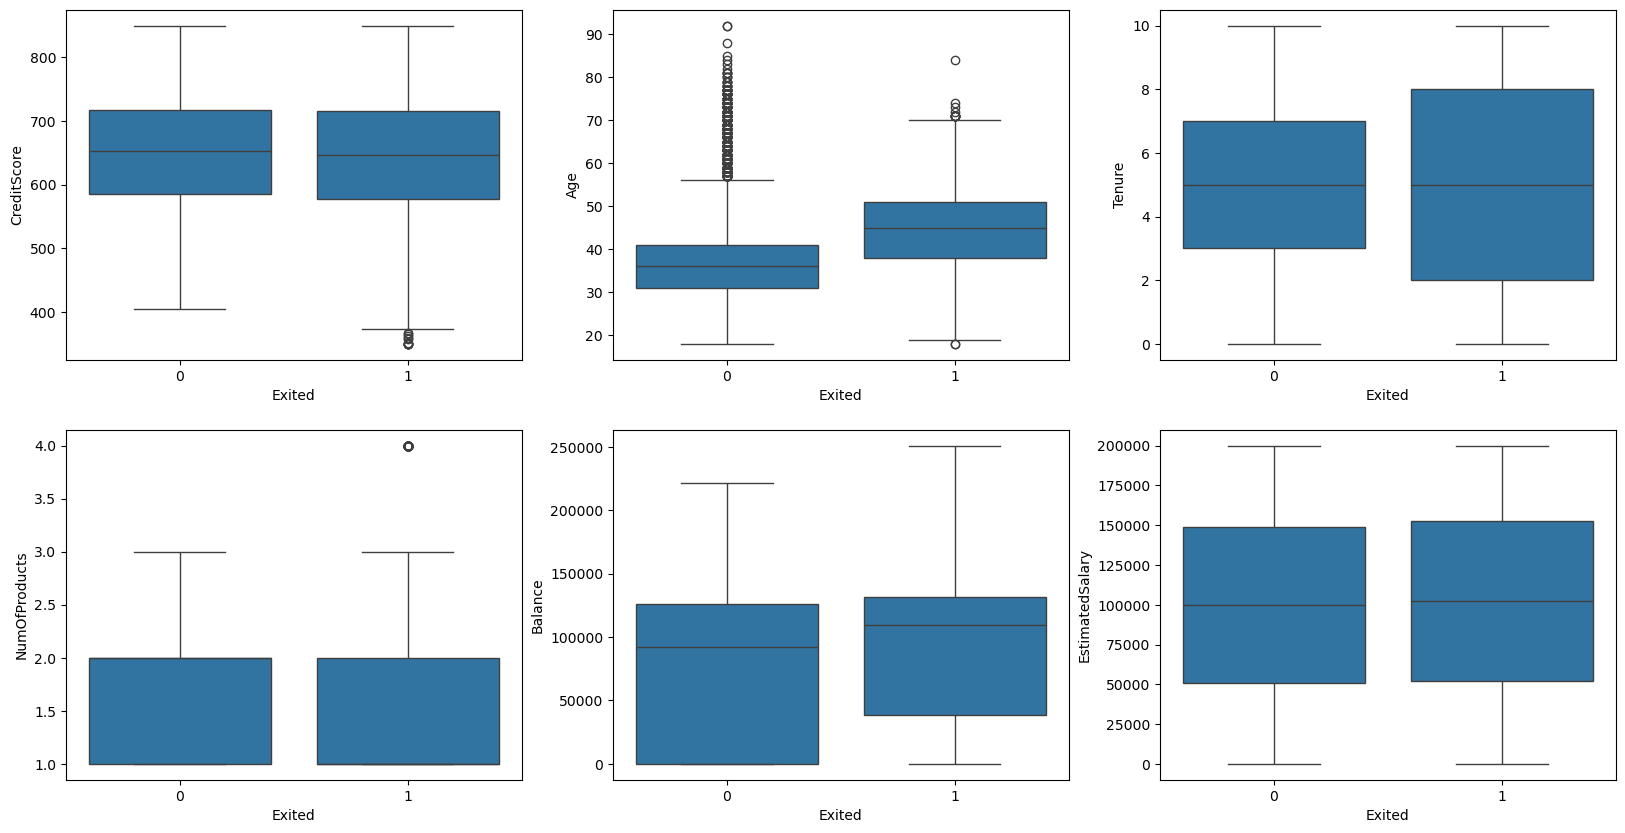

In [7]:
# numerical features vs. churn
_, axss = plt.subplots(2, 3, figsize=[20, 10])
sns.boxplot(x='Exited', y='CreditScore', data=churn_df, ax=axss[0][0])
sns.boxplot(x='Exited', y='Age', data=churn_df, ax=axss[0][1])
sns.boxplot(x='Exited', y='Tenure', data=churn_df, ax=axss[0][2])
sns.boxplot(x='Exited', y='NumOfProducts', data=churn_df, ax=axss[1][0])
sns.boxplot(x='Exited', y='Balance', data=churn_df, ax=axss[1][1])
sns.boxplot(x='Exited', y='EstimatedSalary', data=churn_df, ax=axss[1][2])
plt.show()

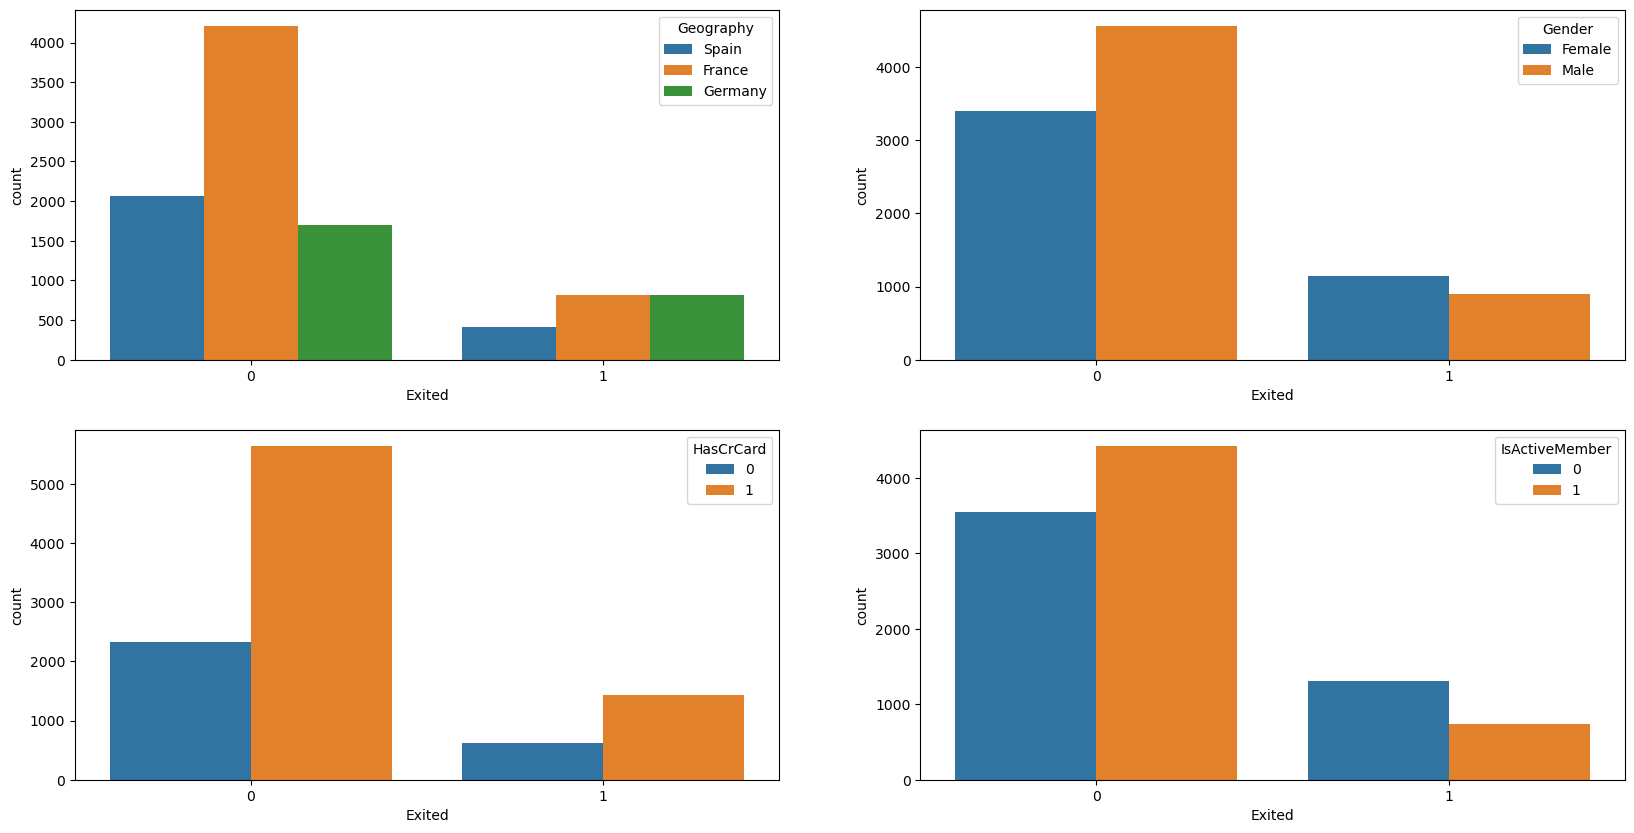

In [8]:
# categorical features vs. churn
_, axss = plt.subplots(2, 2, figsize=[20, 10])
sns.countplot(x='Exited', hue='Geography', data=churn_df, ax=axss[0][0])
sns.countplot(x='Exited', hue='Gender', data=churn_df, ax=axss[0][1])
sns.countplot(x='Exited', hue='HasCrCard', data=churn_df, ax=axss[1][0])
sns.countplot(x='Exited', hue='IsActiveMember', data=churn_df, ax=axss[1][1])
plt.show()

# Part 2: Feature Preprocessing

In [9]:
# drop identifiers and the target to get the feature space
to_drop = ['RowNumber', 'CustomerId', 'Surname', 'Exited']
X = churn_df.drop(to_drop, axis=1)
X.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


In [10]:
X.dtypes

CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
dtype: object

In [11]:
cat_cols = X.columns[X.dtypes == 'object']
num_cols = X.columns[(X.dtypes == 'float64') | (X.dtypes == 'int64')]
print('Categorical:', list(cat_cols))
print('Numerical:', list(num_cols))

Categorical: ['Geography', 'Gender']
Numerical: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


### Train / Test Split

Only ~20% of customers churned, so the split is **stratified** on the target to keep the same class ratio in the training and test sets.

In [12]:
from sklearn import model_selection

# reserve 25% for testing
X_train, X_test, y_train, y_test = model_selection.train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=1)

print('training data has ' + str(X_train.shape[0]) + ' observations with ' + str(X_train.shape[1]) + ' features')
print('test data has ' + str(X_test.shape[0]) + ' observations with ' + str(X_test.shape[1]) + ' features')

training data has 7500 observations with 10 features
test data has 2500 observations with 10 features


### Encode Categorical Features

* `Geography` (3 values): one-hot encoding
* `Gender` (2 values): ordinal encoding

Encoders are fit on the training set only and then applied to the test set.

In [13]:
from sklearn.preprocessing import OneHotEncoder

def OneHotEncoding(df, enc, categories):
    transformed = pd.DataFrame(enc.transform(df[categories]).toarray(),
                               columns=enc.get_feature_names_out(categories))
    return pd.concat([df.reset_index(drop=True), transformed], axis=1).drop(categories, axis=1)

categories = ['Geography']
enc_ohe = OneHotEncoder()
enc_ohe.fit(X_train[categories])

X_train = OneHotEncoding(X_train, enc_ohe, categories)
X_test = OneHotEncoding(X_test, enc_ohe, categories)
X_train.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain
0,633,Male,42,10,0.00,1,0,1,79408.17,0.0,0.0,1.0
1,708,Female,23,4,71433.08,1,1,0,103697.57,0.0,1.0,0.0
2,548,Female,37,9,0.00,2,0,0,98029.58,1.0,0.0,0.0
3,645,Female,48,7,90612.34,1,1,1,149139.13,1.0,0.0,0.0
4,729,Female,45,7,91091.06,2,1,0,71133.12,0.0,0.0,1.0


In [14]:
from sklearn.preprocessing import OrdinalEncoder

categories = ['Gender']
enc_oe = OrdinalEncoder()
enc_oe.fit(X_train[categories])

X_train[categories] = enc_oe.transform(X_train[categories])
X_test[categories] = enc_oe.transform(X_test[categories])
X_train.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain
0,633,1.0,42,10,0.00,1,0,1,79408.17,0.0,0.0,1.0
1,708,0.0,23,4,71433.08,1,1,0,103697.57,0.0,1.0,0.0
2,548,0.0,37,9,0.00,2,0,0,98029.58,1.0,0.0,0.0
3,645,0.0,48,7,90612.34,1,1,1,149139.13,1.0,0.0,0.0
4,729,0.0,45,7,91091.06,2,1,0,71133.12,0.0,0.0,1.0


### Standardize Numerical Features

The scaler is fit on the training set only, so no information from the test set leaks into training.

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train[num_cols])

X_train[num_cols] = scaler.transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
X_train.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain
0,-0.172985,1.0,0.289202,1.731199,-1.218916,-0.912769,-1.542199,0.968496,-0.352044,0.0,0.0,1.0
1,0.602407,0.0,-1.509319,-0.341156,-0.076977,-0.912769,0.648425,-1.032529,0.072315,0.0,1.0,0.0
2,-1.051762,0.0,-0.184093,1.385806,-1.218916,0.796109,-1.542199,-1.032529,-0.026711,1.0,0.0,0.0
3,-0.048922,0.0,0.857156,0.695022,0.229625,-0.912769,0.648425,0.968496,0.866221,1.0,0.0,0.0
4,0.819517,0.0,0.573179,0.695022,0.237278,0.796109,0.648425,-1.032529,-0.496617,0.0,0.0,1.0


# Part 3: Model Training and Result Evaluation

### Part 3.1: Baseline Models

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

classifier_logistic = LogisticRegression()
classifier_KNN = KNeighborsClassifier()
classifier_RF = RandomForestClassifier(random_state=42)

In [17]:
classifier_logistic.fit(X_train, y_train)
print('Baseline Logistic Regression test accuracy:', classifier_logistic.score(X_test, y_test))

Baseline Logistic Regression test accuracy: 0.808


### Part 3.2: Hyperparameter Tuning with Grid Search

Each model is tuned with 5-fold cross-validation on the training set.

In [18]:
from sklearn.model_selection import GridSearchCV

def print_grid_search_metrics(gs):
    print('Best score: ' + str(gs.best_score_))
    print('Best parameters set:')
    best_parameters = gs.best_params_
    for param_name in sorted(best_parameters.keys()):
        print(param_name + ': ' + str(best_parameters[param_name]))

#### Part 3.2.1: Logistic Regression

In [19]:
# penalty: L1 or L2 regularization; C: inverse of regularization strength
parameters = {
    'penalty': ('l2', 'l1'),
    'C': (0.01, 0.05, 0.1, 0.2, 1)
}
Grid_LR = GridSearchCV(LogisticRegression(solver='liblinear'), parameters, cv=5)
Grid_LR.fit(X_train, y_train)
print_grid_search_metrics(Grid_LR)

Best score: 0.8125333333333333
Best parameters set:
C: 1
penalty: l1


In [20]:
best_LR_model = Grid_LR.best_estimator_
best_LR_model.score(X_test, y_test)

0.8092

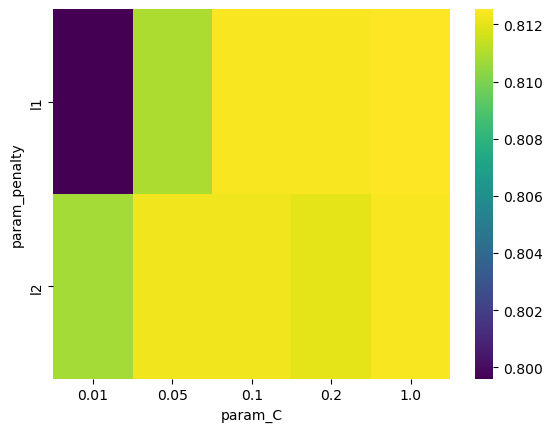

In [21]:
# cross-validated accuracy across the hyperparameter grid
LR_models = pd.DataFrame(Grid_LR.cv_results_)
res = LR_models.pivot(index='param_penalty', columns='param_C', values='mean_test_score')
_ = sns.heatmap(res, cmap='viridis')

#### Part 3.2.2: K-Nearest Neighbors

In [22]:
parameters = {
    'n_neighbors': [1, 3, 5, 7, 9]
}
Grid_KNN = GridSearchCV(KNeighborsClassifier(), parameters, cv=5)
Grid_KNN.fit(X_train, y_train)
print_grid_search_metrics(Grid_KNN)

Best score: 0.8433333333333334
Best parameters set:
n_neighbors: 9


In [23]:
best_KNN_model = Grid_KNN.best_estimator_
best_KNN_model.score(X_test, y_test)

0.8428

#### Part 3.2.3: Random Forest

In [24]:
parameters = {
    'n_estimators': [60, 80, 100],
    'max_depth': [1, 5, 10]
}
Grid_RF = GridSearchCV(RandomForestClassifier(random_state=42), parameters, cv=5)
Grid_RF.fit(X_train, y_train)
print_grid_search_metrics(Grid_RF)

Best score: 0.8645333333333334
Best parameters set:
max_depth: 10
n_estimators: 80


In [25]:
best_RF_model = Grid_RF.best_estimator_
best_RF_model.score(X_test, y_test)

0.8616

### Part 3.3: Model Evaluation - Confusion Matrix (Precision, Recall, Accuracy)

Churn is treated as the positive class.

* **Precision** = TP / (TP + FP): of the customers predicted to churn, the share who actually churned. High precision means few retained customers are flagged as churners.
* **Recall** = TP / (TP + FN): of the customers who actually churned, the share the model caught. High recall means few churners are missed.

In [26]:
from sklearn.metrics import confusion_matrix

def cal_evaluation(classifier, cm):
    tn, fp, fn, tp = cm[0][0], cm[0][1], cm[1][0], cm[1][1]
    accuracy = (tp + tn) / (tp + fp + fn + tn + 0.0)
    precision = tp / (tp + fp + 0.0)
    recall = tp / (tp + fn + 0.0)
    print(classifier)
    print('Accuracy is: ' + str(accuracy))
    print('Precision is: ' + str(precision))
    print('Recall is: ' + str(recall))
    print()

def draw_confusion_matrices(confusion_matrices):
    for classifier, cm in confusion_matrices:
        cal_evaluation(classifier, cm)

In [27]:
confusion_matrices = [
    ('Random Forest', confusion_matrix(y_test, best_RF_model.predict(X_test))),
    ('Logistic Regression', confusion_matrix(y_test, best_LR_model.predict(X_test))),
    ('K Nearest Neighbor', confusion_matrix(y_test, best_KNN_model.predict(X_test)))
]

draw_confusion_matrices(confusion_matrices)

Random Forest
Accuracy is: 0.8616
Precision is: 0.8075471698113208
Recall is: 0.4204322200392927

Logistic Regression
Accuracy is: 0.8092
Precision is: 0.5963855421686747
Recall is: 0.1944990176817289

K Nearest Neighbor
Accuracy is: 0.8428
Precision is: 0.7283464566929134
Recall is: 0.36345776031434185



### Part 3.4: Model Evaluation - ROC & AUC

#### Part 3.4.1: ROC of Random Forest

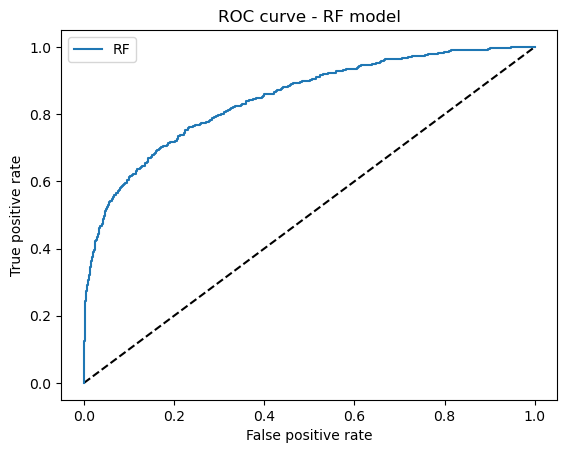

In [28]:
from sklearn.metrics import roc_curve
from sklearn import metrics

y_pred_rf = best_RF_model.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_rf)

plt.figure()
plt.plot([0, 1], [0, 1], 'k--')
plt.plot(fpr_rf, tpr_rf, label='RF')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve - RF model')
plt.legend(loc='best')
plt.show()

In [29]:
# AUC score
metrics.auc(fpr_rf, tpr_rf)

0.8459571016529194

#### Part 3.4.2: ROC of Logistic Regression

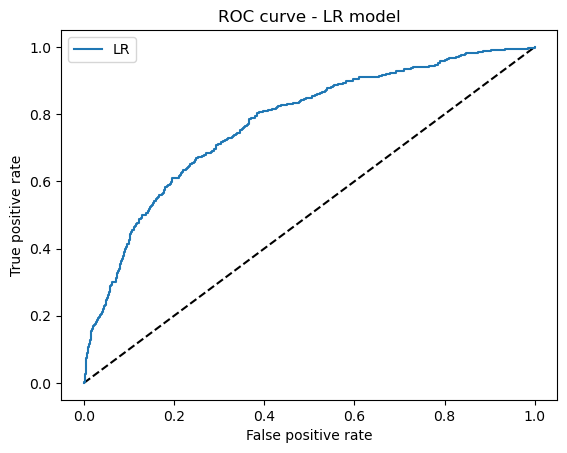

In [30]:
y_pred_lr = best_LR_model.predict_proba(X_test)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_lr)

plt.figure()
plt.plot([0, 1], [0, 1], 'k--')
plt.plot(fpr_lr, tpr_lr, label='LR')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve - LR model')
plt.legend(loc='best')
plt.show()

In [31]:
# AUC score
metrics.auc(fpr_lr, tpr_lr)

0.7722008369687168

# Part 4: Feature Importance

### Part 4.1: Logistic Regression Coefficients

An L2-regularized logistic regression is fit on the standardized full dataset; the absolute size of each coefficient shows how strongly the feature is associated with churn.

In [32]:
X_lr = X.copy()
X_lr = OneHotEncoding(X_lr, enc_ohe, ['Geography'])
X_lr['Gender'] = enc_oe.transform(X_lr[['Gender']])

X_l2 = StandardScaler().fit_transform(X_lr)
LRmodel_l2 = LogisticRegression(penalty='l2', C=0.1, solver='liblinear', random_state=42)
LRmodel_l2.fit(X_l2, y)

indices = np.argsort(abs(LRmodel_l2.coef_[0]))[::-1]

print('Logistic Regression (L2) Coefficients')
for ind in range(X_lr.shape[1]):
    print('{0} : {1}'.format(X_lr.columns[indices[ind]], round(LRmodel_l2.coef_[0][indices[ind]], 4)))

Logistic Regression (L2) Coefficients
Age : 0.751
IsActiveMember : -0.5272
Gender : -0.2591
Geography_Germany : 0.2279
Balance : 0.162
Geography_France : -0.1207
Geography_Spain : -0.089
CreditScore : -0.0637
NumOfProducts : -0.0586
Tenure : -0.0452
EstimatedSalary : 0.0272
HasCrCard : -0.0199


### Part 4.2: Random Forest Feature Importance

In [33]:
X_RF = X.copy()
X_RF = OneHotEncoding(X_RF, enc_ohe, ['Geography'])
X_RF['Gender'] = enc_oe.transform(X_RF[['Gender']])

forest = RandomForestClassifier(random_state=42)
forest.fit(X_RF, y)

importances = forest.feature_importances_
indices = np.argsort(importances)[::-1]

print('Feature importance ranking by Random Forest Model:')
for ind in range(X_RF.shape[1]):
    print('{0} : {1}'.format(X_RF.columns[indices[ind]], round(importances[indices[ind]], 4)))

Feature importance ranking by Random Forest Model:
Age : 0.2401
EstimatedSalary : 0.145
CreditScore : 0.1439
Balance : 0.1429
NumOfProducts : 0.1276
Tenure : 0.0827
IsActiveMember : 0.0404
Geography_Germany : 0.0207
HasCrCard : 0.0186
Gender : 0.0182
Geography_France : 0.0108
Geography_Spain : 0.0091


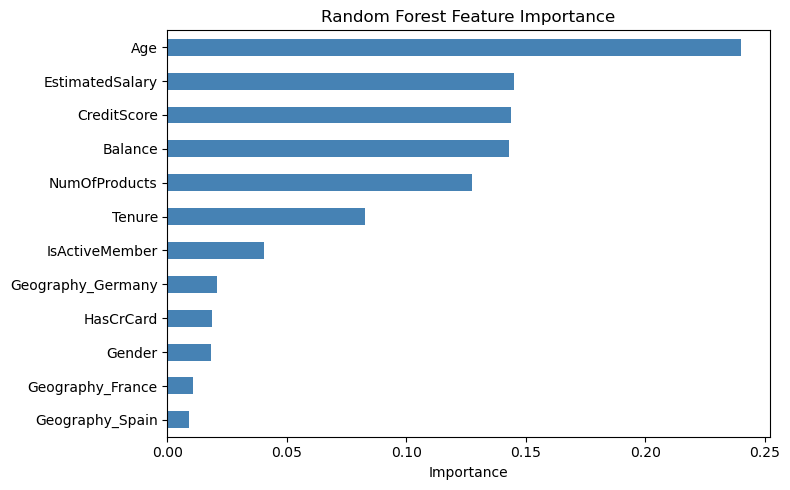

In [34]:
plt.figure(figsize=[8, 5])
pd.Series(importances, index=X_RF.columns).sort_values().plot.barh(color='steelblue')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

# Summary

**Model performance (test set, 2,500 customers):**

| Model | Accuracy | Precision | Recall | AUC |
|---|---|---|---|---|
| Random Forest (max_depth=10, n_estimators=80) | 0.862 | 0.808 | 0.420 | 0.846 |
| K-Nearest Neighbors (k=9) | 0.843 | 0.728 | 0.363 | – |
| Logistic Regression (L1, C=1) | 0.809 | 0.596 | 0.194 | 0.772 |

Random Forest performs best on every metric. Since only ~20% of customers churn, recall is the main area for improvement — options include adjusting the classification threshold, class weighting, or resampling.

**Key churn drivers:**

* **Age** is the strongest predictor in both models: churned customers have a median age of 45 vs. 36 for retained customers.
* **Inactive members** churn at nearly twice the rate of active members (26.9% vs. 14.3%).
* **Customers in Germany** churn at 32.4%, about double France (16.2%) and Spain (16.7%).
* **Female customers** churn more often than male customers (25.1% vs. 16.5%).
* **Number of products** has a non-linear effect: customers with 2 products churn least (7.6%), while those with 3–4 products churn at very high rates.